In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from pathlib import Path

# Locate project directory
current_path = Path.cwd()

if current_path.name == "notebooks":
    project_path = current_path.parent
else:
    project_path = current_path

# Load retail dataset
retail_path = project_path / "data" / "raw" / "retail_all_cities.csv"

retail_df = pd.read_csv(retail_path)

print("Retail dataset loaded successfully!")

Retail dataset loaded successfully!


In [4]:
print(retail_df.head(5))

      retail_id       city      state     store_name           category  \
0  RET_HYD_0001  Hyderabad  Telangana   Fresh Mart 1        Supermarket   
1  RET_HYD_0002  Hyderabad  Telangana  City Market 2        Supermarket   
2  RET_HYD_0003  Hyderabad  Telangana  Daily Needs 3  Convenience Store   
3  RET_HYD_0004  Hyderabad  Telangana  Daily Needs 4     Clothing Store   
4  RET_HYD_0005  Hyderabad  Telangana   Urban Shop 5  Convenience Store   

    latitude  longitude  simulated_daily_visitors data_source  is_synthetic  
0  17.459543  78.347957                       305   Synthetic          True  
1  17.406672  78.262713                       211   Synthetic          True  
2  17.376874  78.260614                       427   Synthetic          True  
3  17.357223  78.361276                        33   Synthetic          True  
4  17.319088  78.312192                       709   Synthetic          True  


In [5]:
retail_df.tail()

,retail_id,city,state,store_name,category,latitude,longitude,simulated_daily_visitors,data_source,is_synthetic
3495,RET_LUC_0346,Lucknow,Uttar Pradesh,Urban Shop 346,Supermarket,26.782714,81.064259,776,Synthetic,True
3496,RET_LUC_0347,Lucknow,Uttar Pradesh,Urban Shop 347,Grocery Store,26.968971,81.045820,1317,Synthetic,True
3497,RET_LUC_0348,Lucknow,Uttar Pradesh,Urban Shop 348,Convenience Store,26.834127,80.922298,242,Synthetic,True
3498,RET_LUC_0349,Lucknow,Uttar Pradesh,Mega Mart 349,Clothing Store,26.900913,80.936756,129,Synthetic,True
3499,RET_LUC_0350,Lucknow,Uttar Pradesh,Urban Shop 350,Supermarket,26.790066,80.896685,378,Synthetic,True


In [6]:
print("Number of rows:", retail_df.shape[0])
print("Number of columns:", retail_df.shape[1])

Number of rows: 3500
Number of columns: 10


In [7]:
retail_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   retail_id                 3500 non-null   object 
 1   city                      3500 non-null   object 
 2   state                     3500 non-null   object 
 3   store_name                3500 non-null   object 
 4   category                  3500 non-null   object 
 5   latitude                  3500 non-null   float64
 6   longitude                 3500 non-null   float64
 7   simulated_daily_visitors  3500 non-null   int64  
 8   data_source               3500 non-null   object 
 9   is_synthetic              3500 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(6)
memory usage: 249.6+ KB


In [8]:
retail_df.describe()

,latitude,longitude,simulated_daily_visitors
count,3500.000000,3500.000000,3500.000000
mean,20.902945,77.789730,767.610857
std,5.332867,4.457645,429.774345
min,12.801335,72.452607,20.000000
25%,17.375400,73.874830,385.000000
50%,20.846366,77.374719,772.000000
75%,26.842017,80.224515,1146.000000
max,28.749778,88.448748,1499.000000


In [9]:
print(retail_df.columns.tolist())

['retail_id', 'city', 'state', 'store_name', 'category', 'latitude', 'longitude', 'simulated_daily_visitors', 'data_source', 'is_synthetic']


In [10]:
# Check missing values in each column
missing_values = retail_df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values:
retail_id                   0
city                        0
state                       0
store_name                  0
category                    0
latitude                    0
longitude                   0
simulated_daily_visitors    0
data_source                 0
is_synthetic                0
dtype: int64

Total Missing Values: 0


In [11]:
# Check complete duplicate rows
print("Duplicate rows:", retail_df.duplicated().sum())

# Check duplicate retail IDs
print("Duplicate Retail IDs:", retail_df["retail_id"].duplicated().sum())

Duplicate rows: 0
Duplicate Retail IDs: 0


In [12]:
category_counts = retail_df["category"].value_counts()

print(category_counts)

category
Clothing Store       885
Supermarket          878
Grocery Store        874
Convenience Store    863
Name: count, dtype: int64


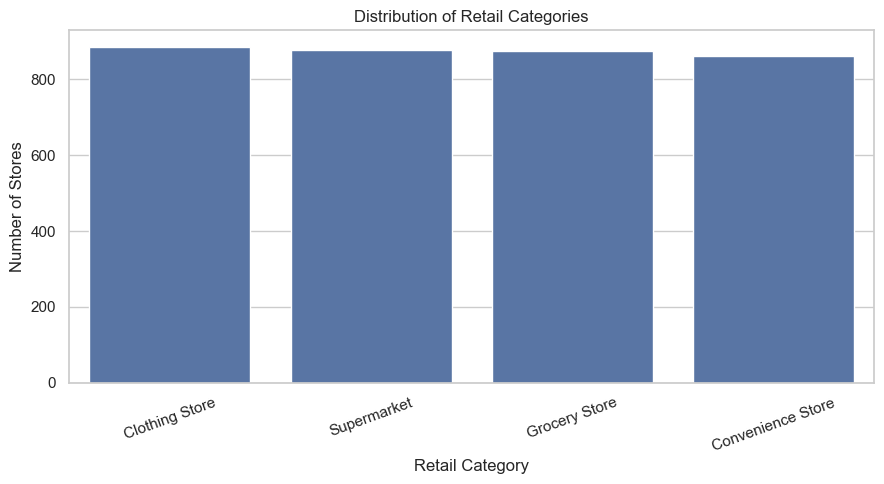

In [13]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=retail_df,
    x="category",
    order=retail_df["category"].value_counts().index
)

plt.title("Distribution of Retail Categories")
plt.xlabel("Retail Category")
plt.ylabel("Number of Stores")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [14]:
city_counts = retail_df["city"].value_counts()

print(city_counts)

city
Hyderabad    350
Bengaluru    350
Chennai      350
Mumbai       350
Delhi        350
Kolkata      350
Pune         350
Ahmedabad    350
Jaipur       350
Lucknow      350
Name: count, dtype: int64


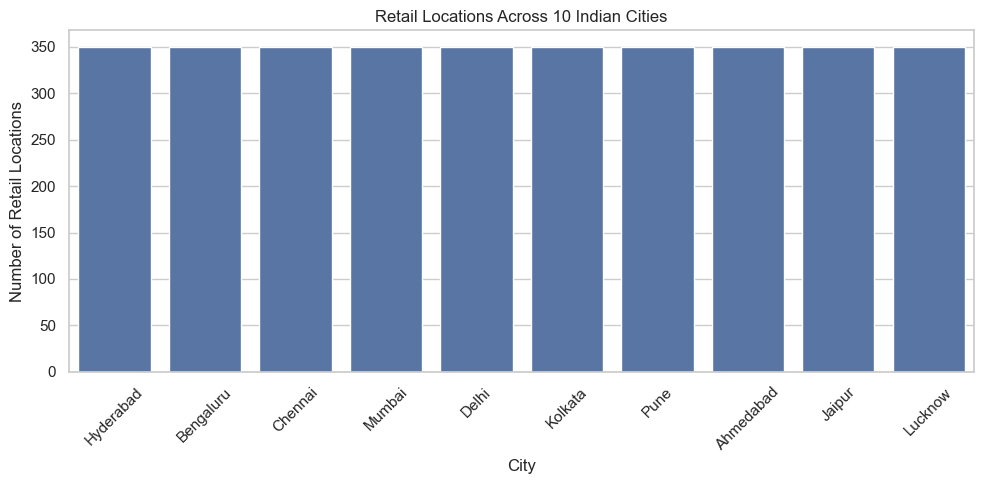

In [15]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=retail_df,
    x="city",
    order=retail_df["city"].value_counts().index
)

plt.title("Retail Locations Across 10 Indian Cities")
plt.xlabel("City")
plt.ylabel("Number of Retail Locations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
print("Latitude Range:")
print("Minimum:", retail_df["latitude"].min())
print("Maximum:", retail_df["latitude"].max())

print("\nLongitude Range:")
print("Minimum:", retail_df["longitude"].min())
print("Maximum:", retail_df["longitude"].max())

Latitude Range:
Minimum: 12.801335
Maximum: 28.749778

Longitude Range:
Minimum: 72.452607
Maximum: 88.448748


In [17]:
retail_df["simulated_daily_visitors"].describe()

count    3500.000000
mean      767.610857
std       429.774345
min        20.000000
25%       385.000000
50%       772.000000
75%      1146.000000
max      1499.000000
Name: simulated_daily_visitors, dtype: float64

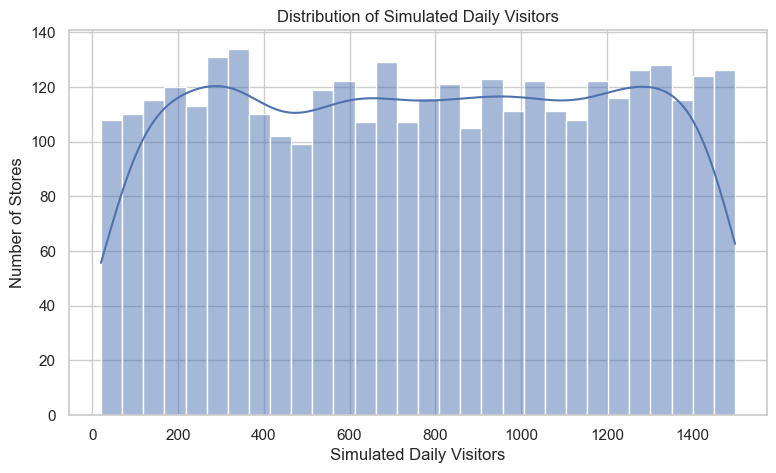

In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=retail_df,
    x="simulated_daily_visitors",
    bins=30,
    kde=True
)

plt.title("Distribution of Simulated Daily Visitors")
plt.xlabel("Simulated Daily Visitors")
plt.ylabel("Number of Stores")
plt.show()

In [19]:
category_visitors = retail_df.groupby("category")[
    "simulated_daily_visitors"
].agg(["count", "mean", "median", "sum"])

category_visitors = category_visitors.sort_values(
    by="mean", ascending=False
)

category_visitors

,count,mean,median,sum
category,,,,
Clothing Store,885,781.510734,788.0,691637
Grocery Store,874,766.248284,765.0,669701
Supermarket,878,764.953303,789.0,671629
Convenience Store,863,757.440324,731.0,653671


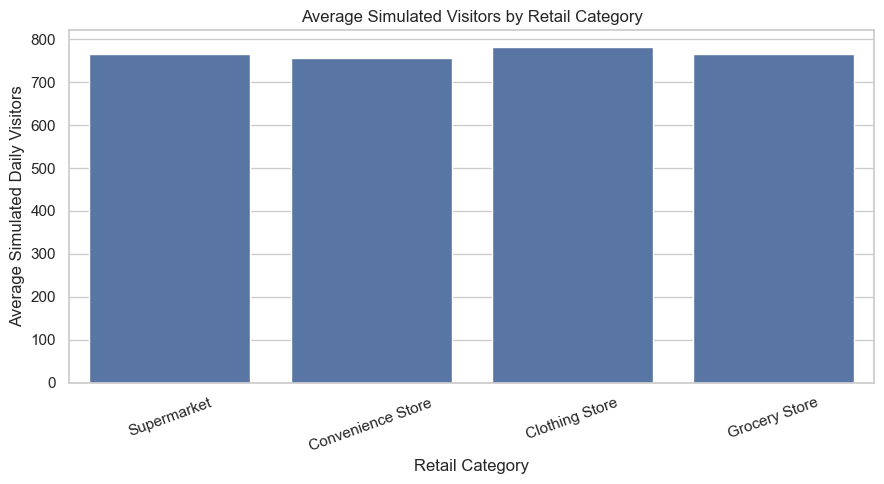

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=retail_df,
    x="category",
    y="simulated_daily_visitors",
    estimator="mean",
    errorbar=None
)

plt.title("Average Simulated Visitors by Retail Category")
plt.xlabel("Retail Category")
plt.ylabel("Average Simulated Daily Visitors")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [21]:
city_visitors = retail_df.groupby("city")[
    "simulated_daily_visitors"
].agg(["count", "mean", "median", "sum"])

city_visitors = city_visitors.sort_values(
    by="mean", ascending=False
)

city_visitors

,count,mean,median,sum
city,,,,
Mumbai,350,797.691429,865.5,279192
Delhi,350,782.965714,795.0,274038
Chennai,350,780.482857,768.0,273169
Bengaluru,350,777.894286,770.5,272263
Hyderabad,350,767.917143,798.0,268771
Kolkata,350,761.874286,770.5,266656
Jaipur,350,753.477143,743.0,263717
Lucknow,350,753.157143,772.0,263605
Pune,350,752.254286,751.0,263289


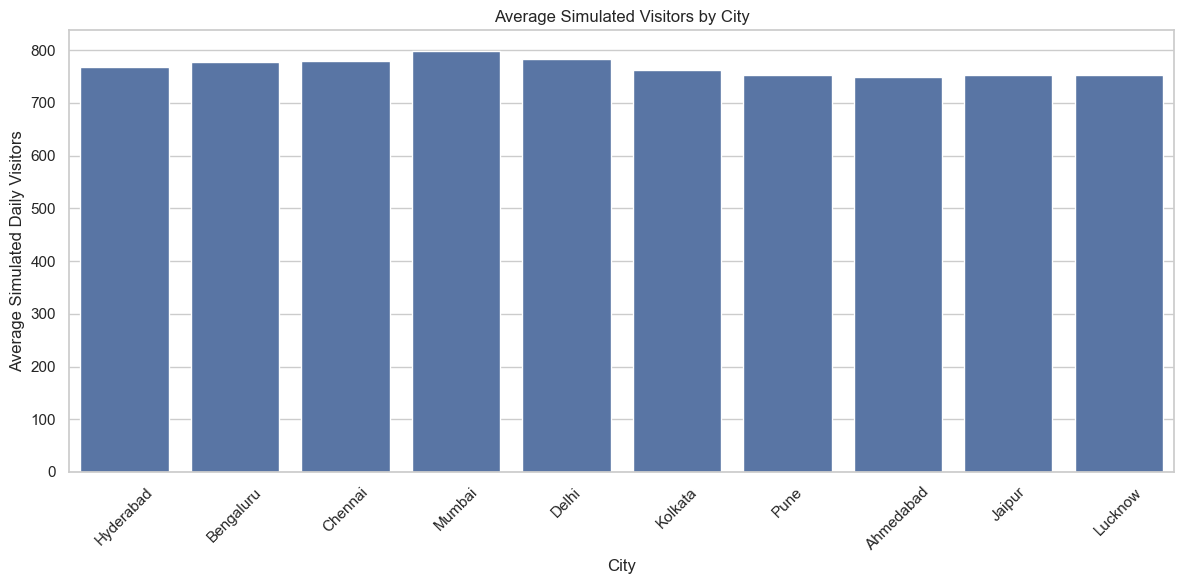

In [22]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=retail_df,
    x="city",
    y="simulated_daily_visitors",
    estimator="mean",
    errorbar=None
)

plt.title("Average Simulated Visitors by City")
plt.xlabel("City")
plt.ylabel("Average Simulated Daily Visitors")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [23]:
# Check latitude and longitude ranges

print("Latitude range:")
print("Minimum:", retail_df["latitude"].min())
print("Maximum:", retail_df["latitude"].max())

print("\nLongitude range:")
print("Minimum:", retail_df["longitude"].min())
print("Maximum:", retail_df["longitude"].max())

Latitude range:
Minimum: 12.801335
Maximum: 28.749778

Longitude range:
Minimum: 72.452607
Maximum: 88.448748


In [24]:
invalid_coordinates = retail_df[
    (~retail_df["latitude"].between(-90, 90)) |
    (~retail_df["longitude"].between(-180, 180))
]

print("Invalid coordinate records:", len(invalid_coordinates))

Invalid coordinate records: 0


In [25]:
print("Visitors less than or equal to zero:",
      (retail_df["simulated_daily_visitors"] <= 0).sum())

Visitors less than or equal to zero: 0


In [26]:
mobility_path = project_path / "data" / "raw" / "mobility_all_cities.csv"

mobility_df = pd.read_csv(mobility_path)

print("Dataset Shape:", mobility_df.shape)

mobility_df.head()

Dataset Shape: (1500, 10)


,mobility_id,city,state,location_name,mobility_type,latitude,longitude,simulated_daily_passengers,data_source,is_synthetic
0,MOB_HYD_0001,Hyderabad,Telangana,Junction Metro Station 1,Metro Station,17.263365,78.554815,3752,Synthetic,True
1,MOB_HYD_0002,Hyderabad,Telangana,East Public Transport Platform 2,Public Transport Platform,17.442882,78.439579,3336,Synthetic,True
2,MOB_HYD_0003,Hyderabad,Telangana,North Metro Station 3,Metro Station,17.414646,78.406057,899,Synthetic,True
3,MOB_HYD_0004,Hyderabad,Telangana,Main Road Bus Stop 4,Bus Stop,17.298326,78.643398,806,Synthetic,True
4,MOB_HYD_0005,Hyderabad,Telangana,Junction Railway Station 5,Railway Station,17.386693,78.456828,3230,Synthetic,True


In [27]:
mobility_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   mobility_id                 1500 non-null   object 
 1   city                        1500 non-null   object 
 2   state                       1500 non-null   object 
 3   location_name               1500 non-null   object 
 4   mobility_type               1500 non-null   object 
 5   latitude                    1500 non-null   float64
 6   longitude                   1500 non-null   float64
 7   simulated_daily_passengers  1500 non-null   int64  
 8   data_source                 1500 non-null   object 
 9   is_synthetic                1500 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(6)
memory usage: 107.1+ KB


In [28]:
mobility_df.describe()

,latitude,longitude,simulated_daily_passengers
count,1500.000000,1500.000000,1500.000000
mean,20.900273,77.790238,2540.094667
std,5.336282,4.461381,1458.675656
min,12.801010,72.450945,50.000000
25%,17.375317,73.874975,1271.000000
50%,20.849466,77.374576,2530.000000
75%,26.823411,80.212258,3845.750000
max,28.749992,88.448980,5000.000000


In [29]:
mobility_df.isnull().sum()

mobility_id                   0
city                          0
state                         0
location_name                 0
mobility_type                 0
latitude                      0
longitude                     0
simulated_daily_passengers    0
data_source                   0
is_synthetic                  0
dtype: int64

In [30]:
print("Total missing values:", mobility_df.isnull().sum().sum())

Total missing values: 0


In [31]:
print("Duplicate rows:", mobility_df.duplicated().sum())

print(
    "Duplicate Mobility IDs:",
    mobility_df["mobility_id"].duplicated().sum()
)

Duplicate rows: 0
Duplicate Mobility IDs: 0


In [32]:
mobility_type_counts = mobility_df["mobility_type"].value_counts()

print(mobility_type_counts)


mobility_type
Bus Stop                     409
Metro Station                372
Public Transport Platform    366
Railway Station              353
Name: count, dtype: int64


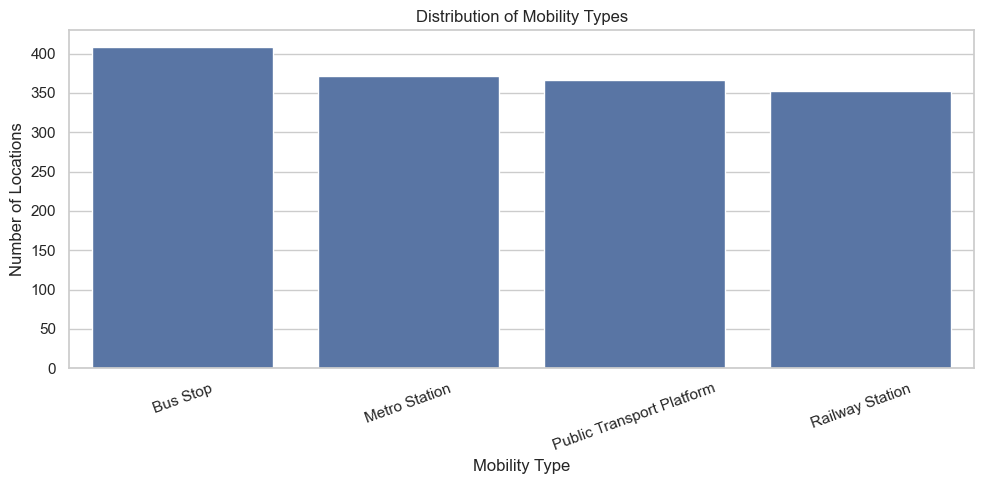

In [33]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=mobility_df,
    x="mobility_type",
    order=mobility_type_counts.index
)

plt.title("Distribution of Mobility Types")
plt.xlabel("Mobility Type")
plt.ylabel("Number of Locations")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [34]:
city_mobility = mobility_df["city"].value_counts()

print(city_mobility)

city
Hyderabad    150
Bengaluru    150
Chennai      150
Mumbai       150
Delhi        150
Kolkata      150
Pune         150
Ahmedabad    150
Jaipur       150
Lucknow      150
Name: count, dtype: int64


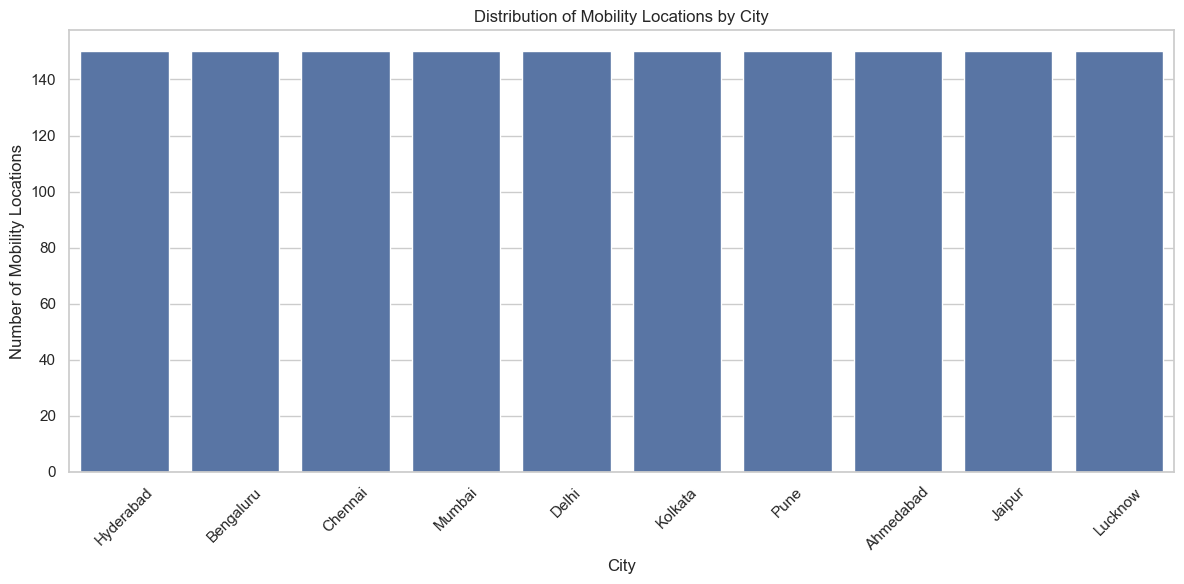

In [35]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=mobility_df,
    x="city",
    order=city_mobility.index
)

plt.title("Distribution of Mobility Locations by City")
plt.xlabel("City")
plt.ylabel("Number of Mobility Locations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
city_passengers = mobility_df.groupby("city")[
    "simulated_daily_passengers"
].agg(["count", "mean", "median", "sum"])

city_passengers = city_passengers.sort_values(
    by="mean", ascending=False
)

city_passengers

,count,mean,median,sum
city,,,,
Ahmedabad,150,2729.940000,2684.0,409491
Mumbai,150,2709.046667,2784.5,406357
Jaipur,150,2562.733333,2740.0,384410
Lucknow,150,2549.806667,2548.5,382471
Chennai,150,2535.993333,2522.5,380399
Kolkata,150,2524.680000,2669.0,378702
Hyderabad,150,2523.326667,2533.0,378499
Pune,150,2493.100000,2462.5,373965
Delhi,150,2419.806667,2394.0,362971


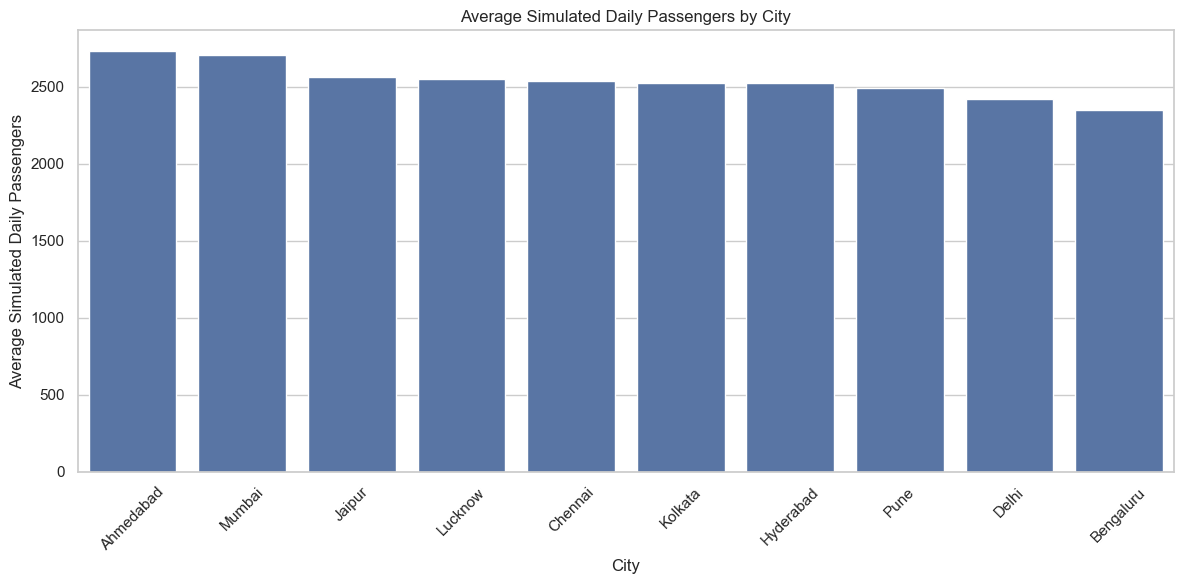

In [37]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=mobility_df,
    x="city",
    y="simulated_daily_passengers",
    estimator="mean",
    errorbar=None,
    order=city_passengers.index
)

plt.title("Average Simulated Daily Passengers by City")
plt.xlabel("City")
plt.ylabel("Average Simulated Daily Passengers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
mobility_type_passengers = mobility_df.groupby("mobility_type")[
    "simulated_daily_passengers"
].agg(["count", "mean", "median", "sum"])

mobility_type_passengers = mobility_type_passengers.sort_values(
    by="mean", ascending=False
)

mobility_type_passengers

,count,mean,median,sum
mobility_type,,,,
Bus Stop,409,2659.085575,2853.0,1087566
Metro Station,372,2534.123656,2531.0,942694
Railway Station,353,2508.762040,2474.0,885593
Public Transport Platform,366,2443.412568,2350.5,894289


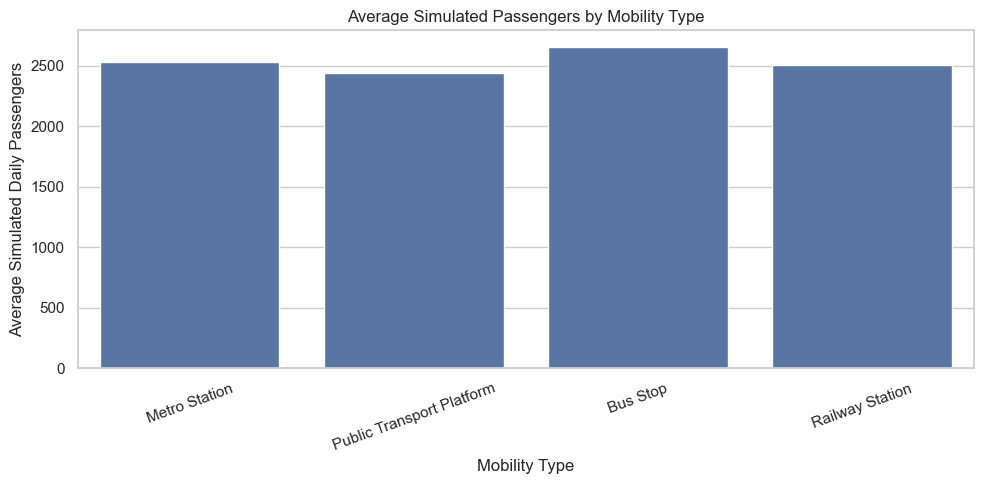

In [39]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=mobility_df,
    x="mobility_type",
    y="simulated_daily_passengers",
    estimator="mean",
    errorbar=None
)

plt.title("Average Simulated Passengers by Mobility Type")
plt.xlabel("Mobility Type")
plt.ylabel("Average Simulated Daily Passengers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [40]:
# 1. Check invalid coordinates
invalid_coordinates = mobility_df[
    (~mobility_df["latitude"].between(-90, 90)) |
    (~mobility_df["longitude"].between(-180, 180))
]

# 2. Check invalid passenger counts
invalid_passengers = mobility_df[
    mobility_df["simulated_daily_passengers"] <= 0
]

# 3. Check synthetic labels
synthetic_check = mobility_df["is_synthetic"].value_counts()

print("Invalid coordinates:", len(invalid_coordinates))
print("Invalid passenger records:", len(invalid_passengers))
print("\nSynthetic label distribution:")
print(synthetic_check)

Invalid coordinates: 0
Invalid passenger records: 0

Synthetic label distribution:
is_synthetic
True    1500
Name: count, dtype: int64


In [41]:
retail_summary = {
    "Dataset": "Retail",
    "Total Records": len(retail_df),
    "Total Cities": retail_df["city"].nunique(),
    "Missing Values": retail_df.isnull().sum().sum(),
    "Duplicate Rows": retail_df.duplicated().sum()
}

mobility_summary = {
    "Dataset": "Mobility",
    "Total Records": len(mobility_df),
    "Total Cities": mobility_df["city"].nunique(),
    "Missing Values": mobility_df.isnull().sum().sum(),
    "Duplicate Rows": mobility_df.duplicated().sum()
}

eda_summary = pd.DataFrame([
    retail_summary,
    mobility_summary
])

eda_summary

,Dataset,Total Records,Total Cities,Missing Values,Duplicate Rows
0,Retail,3500,10,0,0
1,Mobility,1500,10,0,0


In [42]:
report_path = project_path / "reports" / "eda_summary.csv"

eda_summary.to_csv(report_path, index=False)

print("EDA summary saved successfully!")
print(report_path)

EDA summary saved successfully!
C:\Users\aravi\GeoPulse-Retail-Mobility-Analytics\reports\eda_summary.csv


In [43]:
# Load raw and processed retail datasets

raw_retail = pd.read_csv(
    project_path / "data" / "raw" / "retail_all_cities.csv"
)

processed_retail = pd.read_csv(
    project_path / "data" / "processed" / "india_retail_locations.csv"
)

# Compare datasets

print("Raw Retail Shape:", raw_retail.shape)
print("Processed Retail Shape:", processed_retail.shape)

print(
    "Are both datasets identical?",
    raw_retail.equals(processed_retail)
)

Raw Retail Shape: (3500, 10)
Processed Retail Shape: (3500, 10)
Are both datasets identical? True


In [44]:
# Create a separate working copy

retail_cleaned = raw_retail.copy()

print("Original records:", len(raw_retail))
print("Working copy records:", len(retail_cleaned))

Original records: 3500
Working copy records: 3500


In [45]:
# Clean unnecessary spaces in text columns

text_columns = [
    "city",
    "state",
    "store_name",
    "category",
    "data_source"
]

for col in text_columns:
    retail_cleaned[col] = (
        retail_cleaned[col]
        .astype("string")
        .str.strip()
    )

print("Text standardization completed.")

Text standardization completed.


In [46]:
# Remove duplicate complete rows

before = len(retail_cleaned)

retail_cleaned = retail_cleaned.drop_duplicates()

after = len(retail_cleaned)

print("Duplicate rows removed:", before - after)
print("Remaining records:", after)

Duplicate rows removed: 0
Remaining records: 3500


In [47]:
before = len(retail_cleaned)

retail_cleaned = retail_cleaned.drop_duplicates(
    subset=["retail_id"]
)

after = len(retail_cleaned)

print("Duplicate Retail IDs removed:", before - after)
print("Remaining records:", after)

Duplicate Retail IDs removed: 0
Remaining records: 3500


In [48]:
missing_values = retail_cleaned.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
retail_id                   0
city                        0
state                       0
store_name                  0
category                    0
latitude                    0
longitude                   0
simulated_daily_visitors    0
data_source                 0
is_synthetic                0
dtype: int64

Total missing values: 0


In [49]:
invalid_coordinates = retail_cleaned[
    (~retail_cleaned["latitude"].between(-90, 90)) |
    (~retail_cleaned["longitude"].between(-180, 180))
]

print("Invalid coordinate records:", len(invalid_coordinates))

Invalid coordinate records: 0


In [50]:
invalid_visitors = retail_cleaned[
    retail_cleaned["simulated_daily_visitors"] <= 0
]

print("Invalid visitor records:", len(invalid_visitors))

Invalid visitor records: 0


In [51]:
required_columns = [
    "retail_id",
    "city",
    "state",
    "store_name",
    "category"
]

for col in required_columns:
    retail_cleaned[col] = retail_cleaned[col].astype("string").str.strip()

    empty_count = (
        retail_cleaned[col].isna() |
        retail_cleaned[col].eq("")
    ).sum()

    print(f"{col}: {empty_count} empty values")

retail_id: 0 empty values
city: 0 empty values
state: 0 empty values
store_name: 0 empty values
category: 0 empty values


In [52]:
processed_path = project_path / "data" / "processed" / "india_retail_locations.csv"

retail_cleaned.to_csv(processed_path, index=False)

print("Cleaned retail dataset saved successfully!")
print("File location:", processed_path)
print("Final dataset shape:", retail_cleaned.shape)

Cleaned retail dataset saved successfully!
File location: C:\Users\aravi\GeoPulse-Retail-Mobility-Analytics\data\processed\india_retail_locations.csv
Final dataset shape: (3500, 10)


In [53]:
verified_retail = pd.read_csv(processed_path)

print("Saved dataset shape:", verified_retail.shape)
print("Duplicate rows:", verified_retail.duplicated().sum())
print("Missing values:", verified_retail.isnull().sum().sum())
print("Duplicate Retail IDs:", verified_retail["retail_id"].duplicated().sum())

Saved dataset shape: (3500, 10)
Duplicate rows: 0
Missing values: 0
Duplicate Retail IDs: 0


In [54]:
mobility_path = project_path / "data" / "raw" / "mobility_all_cities.csv"

raw_mobility = pd.read_csv(mobility_path)

print("Original mobility records:", len(raw_mobility))
print("Dataset shape:", raw_mobility.shape)
print("\nColumn names:")
print(raw_mobility.columns.tolist())

Original mobility records: 1500
Dataset shape: (1500, 10)

Column names:
['mobility_id', 'city', 'state', 'location_name', 'mobility_type', 'latitude', 'longitude', 'simulated_daily_passengers', 'data_source', 'is_synthetic']


In [55]:
mobility_cleaned = raw_mobility.copy()

print("Original records:", len(raw_mobility))
print("Working copy records:", len(mobility_cleaned))

Original records: 1500
Working copy records: 1500


In [56]:
text_columns = [
    "city",
    "state",
    "location_name",
    "mobility_type",
    "data_source"
]

for col in text_columns:
    mobility_cleaned[col] = (
        mobility_cleaned[col]
        .astype("string")
        .str.strip()
    )

print("Mobility text standardization completed.")

Mobility text standardization completed.


In [57]:
before = len(mobility_cleaned)

mobility_cleaned = mobility_cleaned.drop_duplicates()

after = len(mobility_cleaned)

print("Duplicate rows removed:", before - after)
print("Remaining records:", after)

Duplicate rows removed: 0
Remaining records: 1500


In [58]:
before = len(mobility_cleaned)

mobility_cleaned = mobility_cleaned.drop_duplicates(
    subset=["mobility_id"]
)

after = len(mobility_cleaned)

print("Duplicate Mobility IDs removed:", before - after)
print("Remaining records:", after)

Duplicate Mobility IDs removed: 0
Remaining records: 1500


In [59]:
print("Duplicate rows:", mobility_cleaned.duplicated().sum())

Duplicate rows: 0


In [60]:
invalid_coordinates = mobility_cleaned[
    (~mobility_cleaned["latitude"].between(-90, 90)) |
    (~mobility_cleaned["longitude"].between(-180, 180))
]

print("Invalid coordinate records:", len(invalid_coordinates))

Invalid coordinate records: 0


In [61]:
invalid_passengers = mobility_cleaned[
    mobility_cleaned["simulated_daily_passengers"] <= 0
]

print("Invalid passenger records:", len(invalid_passengers))

Invalid passenger records: 0


In [62]:
required_columns = [
    "mobility_id",
    "city",
    "state",
    "location_name",
    "mobility_type"
]

for col in required_columns:
    mobility_cleaned[col] = (
        mobility_cleaned[col]
        .astype("string")
        .str.strip()
    )

    empty_count = (
        mobility_cleaned[col].isna() |
        mobility_cleaned[col].eq("")
    ).sum()

    print(f"{col}: {empty_count} empty values")

mobility_id: 0 empty values
city: 0 empty values
state: 0 empty values
location_name: 0 empty values
mobility_type: 0 empty values


In [63]:
processed_mobility_path = (
    project_path / "data" / "processed" / "india_mobility_locations.csv"
)

mobility_cleaned.to_csv(
    processed_mobility_path,
    index=False
)

print("Cleaned mobility dataset saved successfully!")
print("File location:", processed_mobility_path)
print("Final dataset shape:", mobility_cleaned.shape)

Cleaned mobility dataset saved successfully!
File location: C:\Users\aravi\GeoPulse-Retail-Mobility-Analytics\data\processed\india_mobility_locations.csv
Final dataset shape: (1500, 10)


In [ ]:
verified_mobility = pd.read_csv(processed_mobility_path)

print("Saved dataset shape:", verified_mobility.shape)
print("Duplicate rows:", verified_mobility.duplicated().sum())
print("Missing values:", verified_mobility.isnull().sum().sum())
print(
    "Duplicate Mobility IDs:",
    verified_mobility["mobility_id"].duplicated().sum()
)